In [22]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd


import project_images_loader as pil
from data_loader import DataLoader
import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc

import itk


In [23]:
INAME_REGISTERED = "{0}_{1}_T1_VOXELMORPH2.nii.gz"
# DFIELD_NAME = "{0}_{1}_DFIELD_{2}.nii.gz"
# MASK_REGISTERED = "{0}_{1}_BMASK_{2}.nii.gz"

# INAME_REGISTERED_NSK = "{0}_{1}_T1_{2}_NSK.nii"
# DFIELD_NAME_NSK = "{0}_{1}_DFIELD_{2}_NSK.nii"

In [24]:


def load_nsk_image(hunt, id):
    if hunt == pil.HUNTS[0]:
        _img, _ = nfc.load_nifti(f"{current_path}/images/{INAME_REGISTERED.format(id, hunt-3)}")
        img = np.zeros((193,229,193))
        img[:192, :224, :192] = _img
        # mask, _ = nfc.load_nifti(pil.get_brain_mask_path_name(4, id, pil.REGISTRATION_TO_MNI, absolute=True))
    elif hunt == pil.HUNTS[1]:
        img, _ = nfc.load_nifti(pil.get_registered_to_template_image_path_name(4, id, pil.REGISTRATION_TO_MNI, absolute=True))
        mask, _ = nfc.load_nifti(pil.get_brain_mask_path_name(4, id, pil.REGISTRATION_TO_MNI, absolute=True))
        img = util.skull_stripping_and_normalize(img, mask, percentile=(0,100))
    return img


def load_nsk_image2(hunt, id):
    img, _ = nfc.load_nifti(pil.get_registered_to_template_image_path_name(hunt, id, pil.REGISTRATION_TO_MNI, absolute=True))
    mask, _ = nfc.load_nifti(pil.get_brain_mask_path_name(hunt, id, pil.REGISTRATION_TO_MNI, absolute=True))
    img = util.skull_stripping_and_normalize(img, mask, percentile=(0,100))
    return img

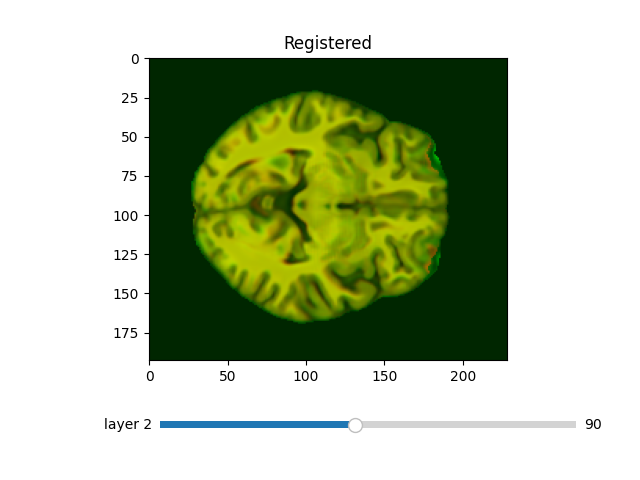

In [25]:
def visualize_pairwise():
    %matplotlib widget
    for id in [pil.get_matching_ids()[0]]:
        image_size = (193,229,193)
        img_sum = np.zeros((image_size)+(3,), dtype=np.float32)
        for hunt in pil.HUNTS:
            img = load_nsk_image(hunt, id)
            img_sum[...,hunt-3] += img[:image_size[0], :image_size[1], :image_size[2]]
        fc.imgshow_3D(f"Registered", img_sum, current_plane=90)

# visualize_pairwise("0026")
visualize_pairwise()


In [26]:
def compute_pairwise_similarity_metrics():
    metrics_list = []
    # for id in pil.get_matching_ids():
    for id in [pil.get_matching_ids()[0]]:

        img_HUNT3 = load_nsk_image(3, id)
        img_HUNT4 = load_nsk_image(4, id)

        metrics = util.get_metrics_dict(img_HUNT3, img_HUNT4)
        metrics_list.append(metrics)

    df = pd.DataFrame(metrics_list)
    return df


# df_MNI_26 = compute_pairwise_similarity_metrics("0026")
# print(df_MNI_26.head(10))

df_MNI_38 = compute_pairwise_similarity_metrics()
print(df_MNI_38.head(10))


# Skull stripping and normalization for metrics
# "0026"
#         rms       ncc        mi      ssim
# 0  0.000005  0.996692  1.119193  0.992383
# 1  0.000004  0.997615  1.101900  0.992873
# 2  0.000015  0.997343  1.066028  0.960878
# 3  0.000004  0.997215  1.080723  0.993525
# 4  0.000006  0.997633  1.167223  0.986028
# 5  0.000006  0.996965  1.135214  0.989997
# 6  0.000012  0.997506  1.035217  0.974009
# 7  0.000006  0.997464  1.150267  0.991973
# 8  0.000010  0.997864  1.035779  0.979579
# "0038"
#         rms       ncc        mi      ssim
# 0  0.000004  0.998416  1.166446  0.994710
# 1  0.000005  0.998417  1.147372  0.991109
# 2  0.000015  0.998356  1.112659  0.955849
# 3  0.000003  0.998455  1.125624  0.995560
# 4  0.000006  0.998417  1.212504  0.987091
# 5  0.000004  0.998161  1.180646  0.992739
# 6  0.000010  0.998367  1.077480  0.981250
# 7  0.000006  0.998319  1.195469  0.993835
# 8  0.000009  0.998568  1.075229  0.984085

#                 rms       ncc        mi      ssim
# df_MNI_26  0.000008  0.997366  1.099060  0.984583
# df_MNI_38  0.000007  0.998386  1.143714  0.986248



# Whole images for metrics
# "0026"
#         rms       ncc        mi      ssim
# 0  0.004602  0.923362  1.687801  0.811274
# 1  0.005274  0.906526  1.654232  0.761426
# 2  0.004645  0.922151  1.866578  0.822758
# 3  0.004665  0.933271  1.606120  0.760096
# 4  0.004749  0.920276  1.863942  0.798728
# 5  0.004471  0.929670  1.717267  0.790254
# 6  0.006994  0.862404  1.356403  0.710921
# 7  0.004641  0.927229  1.799449  0.806942
# 8  0.005138  0.922230  1.750302  0.820201
# "0038"
#         rms       ncc        mi      ssim
# 0  0.004614  0.923002  1.719037  0.809364
# 1  0.005220  0.908351  1.684320  0.763441
# 2  0.004610  0.923428  1.905531  0.822229
# 3  0.004923  0.925755  1.624618  0.752904
# 4  0.004695  0.921884  1.891213  0.801403
# 5  0.004463  0.929812  1.751434  0.791418
# 6  0.006725  0.872792  1.414141  0.717361
# 7  0.004787  0.922573  1.833930  0.802173
# 8  0.004963  0.927484  1.808860  0.826728

#                rms       ncc        mi      ssim
# df_MNI_26  0.00502  0.916347  1.700233  0.786956
# df_MNI_38  0.00500  0.917231  1.737009  0.787447



#         rms       ncc        mi      ssim
# 0  0.000009  0.993514  1.176744  0.974099

        rms       ncc        mi      ssim
0  0.000091  0.953733  1.023862  0.183029


In [19]:
df_means = pd.DataFrame({
    'df_MNI_26': df_MNI_26.mean(),
    'df_MNI_38': df_MNI_38.mean(),
})
df_means = df_means.transpose()
print(df_means)


                rms       ncc        mi      ssim
df_MNI_26  0.000008  0.997366  1.099060  0.984583
df_MNI_38  0.000007  0.998386  1.143714  0.986248


In [6]:
%matplotlib widget




id = pil.test_patients_ids[1]
reg_file = "0038"
# img_nsk, _ = nfc.load_nifti(f"{current_path}/images/{INAME_REGISTERED_NSK.format(id, 0, reg_file)}")
img, _ = nfc.load_nifti(f"{current_path}/images/{INAME_REGISTERED.format(id, 0, reg_file)}")
mask, _ = nfc.load_nifti(pil.get_brain_mask_path_name(3, id, pil.REGISTRATION_TO_MNI, absolute=True))

img_fixed, _ = nfc.load_nifti(pil.get_registered_to_template_image_path_name(4, id, pil.REGISTRATION_TO_MNI, absolute=True))
mask_fixed, _ = nfc.load_nifti(pil.get_brain_mask_path_name(4, id, pil.REGISTRATION_TO_MNI, absolute=True))

# img_nsk = util.skull_stripping_and_normalize(img_nsk, mask)
img = util.skull_stripping_and_normalize(img, mask_fixed)
img_fixed = util.skull_stripping_and_normalize(img_fixed, mask_fixed)

# print(np.sum(img_nsk-img))

# metrics_nsk = util.get_metrics_dict(img_nsk, img_fixed)
metrics = util.get_metrics_dict(img, img_fixed)

# print(metrics_nsk)
print(metrics)
# fc.imgshow_3D("", img)
# fc.imgshow_3D("", img_nsk)

# {'rms': 4.2846324809799265e-05, 'ncc': 0.966257011186644, 'mi': 1.076949690524152, 'ssim': 0.2079401334551534}
# {'rms': 7.883989790990728e-06, 'ncc': 0.9919133344861987, 'mi': 1.080058916032581, 'ssim': 0.9798660760874578}
# {'rms': 4.037037498704882e-06, 'ncc': 0.9984159567810479, 'mi': 1.1664458788520435, 'ssim': 0.9947097037952904}

{'rms': 5.2928538527006424e-06, 'ncc': 0.998417203304022, 'mi': 1.1473721853413874, 'ssim': 0.9911093139164086}


[[   1.    0.    0.  -96.]
 [   0.    1.    0. -132.]
 [   0.    0.    1.  -78.]
 [   0.    0.    0.    1.]]


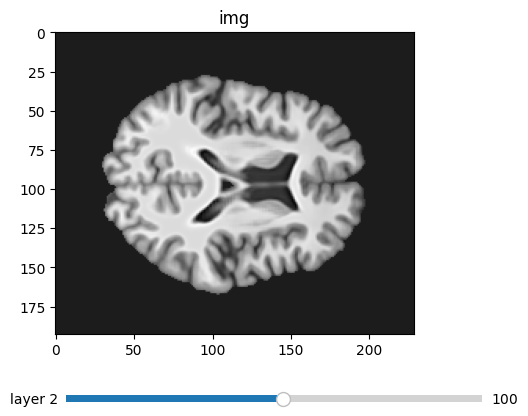

In [5]:
id = pil.test_patients_ids[0]
fixed_image, affine = nfc.load_nifti(pil.get_registered_to_template_image_path_name(4, id, pil.REGISTRATION_TO_MNI, absolute=True))
fixed_mask, _ = nfc.load_nifti(pil.get_brain_mask_path_name(4, id, pil.REGISTRATION_TO_MNI, absolute=True))

# fixed_image_array = itk.array_from_image(fixed_image)
# fixed_mask_array = itk.array_from_image(fixed_mask)

print(affine)
fixed_image = util.skull_stripping_and_normalize(fixed_image, fixed_mask)
fc.imgshow_3D("img", fixed_image)

# _fixed_image = itk.image_view_from_array(fixed_image_array)
# _fixed_image.CopyInformation(fixed_image)

# fixed_image_itk = nfc.numpy_array2itk_image(fixed_image, affine)
# # Obtener los metadatos individuales
# spacing = fixed_image_itk.GetSpacing()
# origin = fixed_image_itk.GetOrigin()
# direction = fixed_image_itk.GetDirection()
# size = fixed_image_itk.GetLargestPossibleRegion().GetSize()

# # Imprimir los metadatos
# print("Spacing:", spacing)
# print("Origin:", origin)
# print("Direction:", direction)
# print("Size:", size)
